<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 3: Student Placement Prediction

## Import libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

## Load and analyse data

In [ ]:
df = pd.read_csv('/content/indian_engineering_placement_2026.csv')

In [ ]:
print("\nSample data:\n",df.sample(5))
print("\nShape:\n",df.shape)
print("\nInfo:\n", df.info())
print("\nDescribe:\n", df.describe())
print("\nMissing values per column:\n",df.isnull().sum())
print("\nDuplicated values:\n", df.duplicated().sum())



Sample data:
       Student_ID  Age  Gender           State    Branch College_Tier  CGPA  \
7202     ST07203   18    Male   Uttar Pradesh  Chemical       Tier-3  8.19   
11937    ST11938   25  Female     West Bengal      AIML       Tier-2  7.17   
6573     ST06574   21    Male     Maharashtra      AIML       Tier-3  6.99   
10422    ST10423   21    Male      Tamil Nadu       CSE       Tier-2  7.21   
6152     ST06153   21  Female  Andhra Pradesh       EEE       Tier-2  7.93   

       Attendance_Percentage  DSA_Problems_Solved  Aptitude_Score  ...  \
7202                   71.37                  101              28  ...   
11937                  75.13                  205              69  ...   
6573                   72.66                  167              26  ...   
10422                  64.66                  170              21  ...   
6152                   67.63                  126              28  ...   

       GitHub_Contributions  LinkedIn_Activity_Score  Hackathons_Partic

In [ ]:
# drop duplicate rows from dataframe
df = df.drop_duplicates()


In [ ]:
# Since the "Open_Source_Contributions" and "LinkedIn_Activity_Score" have null values, so filled them with
# median and mean
median_os = df["Open_Source_Contributions"].median
df["Open_Source_Contributions"] = df["Open_Source_Contributions"].fillna(median_os)

mean_linkedin = df["LinkedIn_Activity_Score"].mean
df["LinkedIn_Activity_Score"] = df["LinkedIn_Activity_Score"].fillna(mean_linkedin)

## Visualising the data

In [ ]:
# Selecting numerical features from the data based on their data type
numerical_features = df.select_dtypes(include=["float64", "int64"])


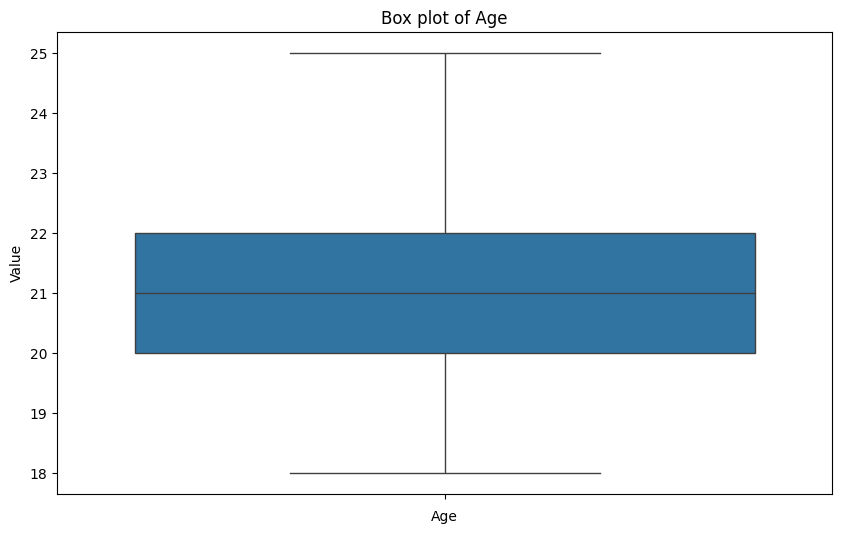

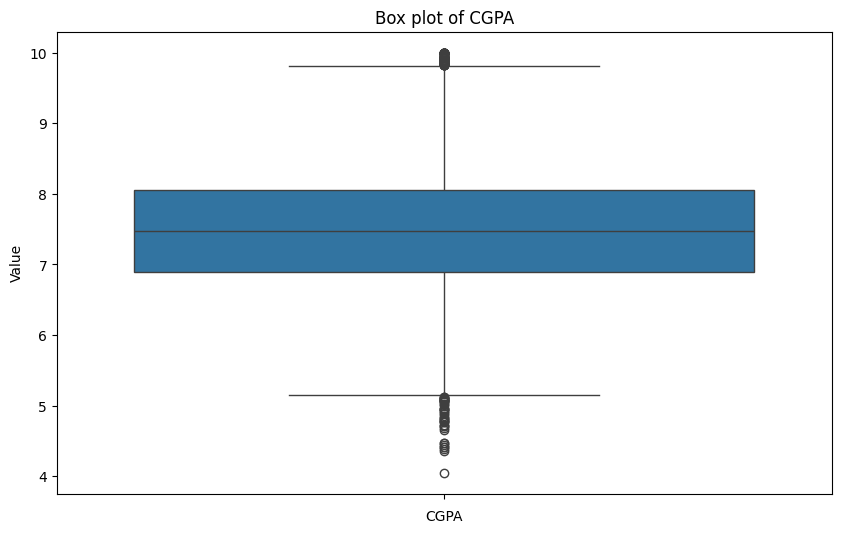

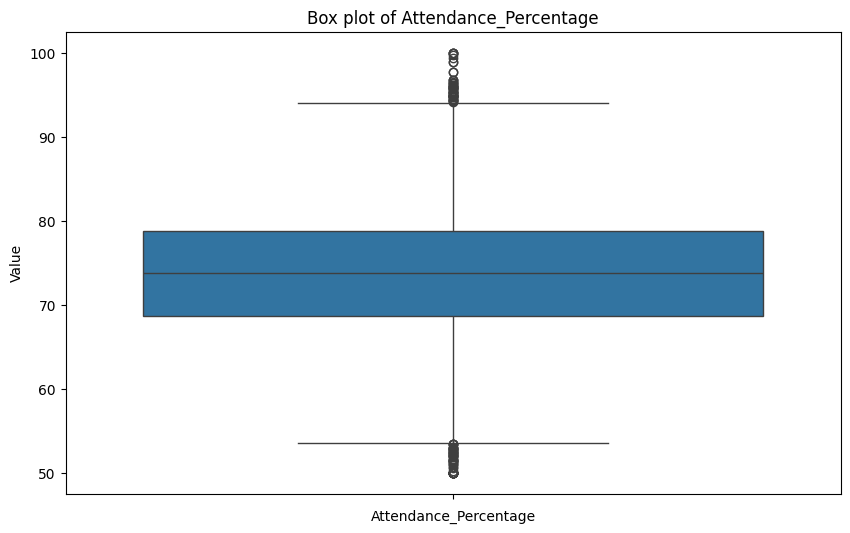

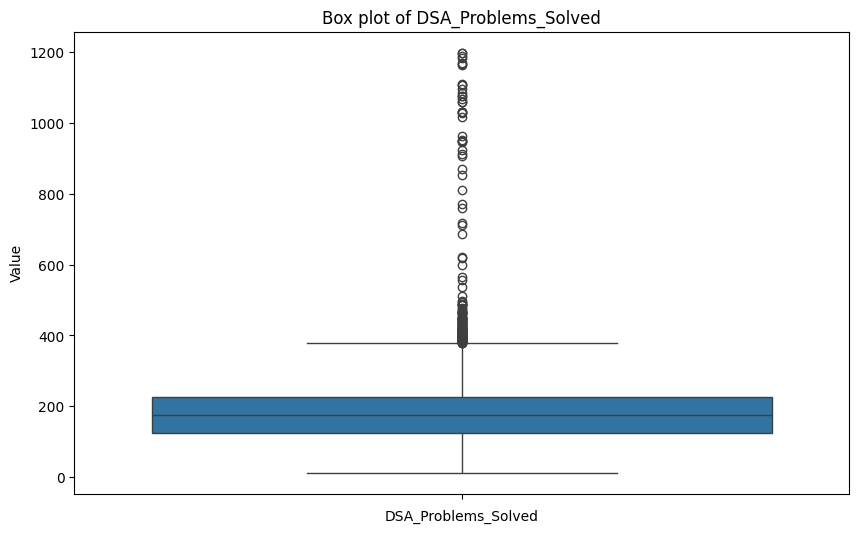

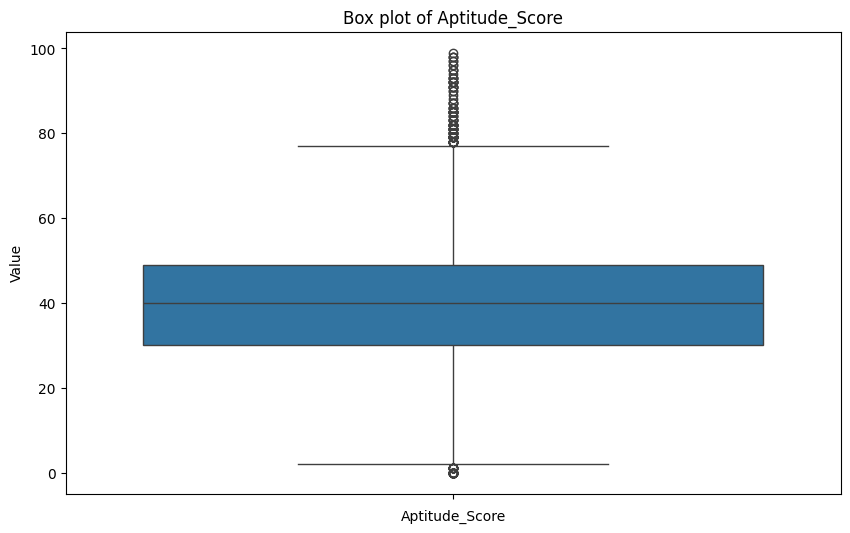

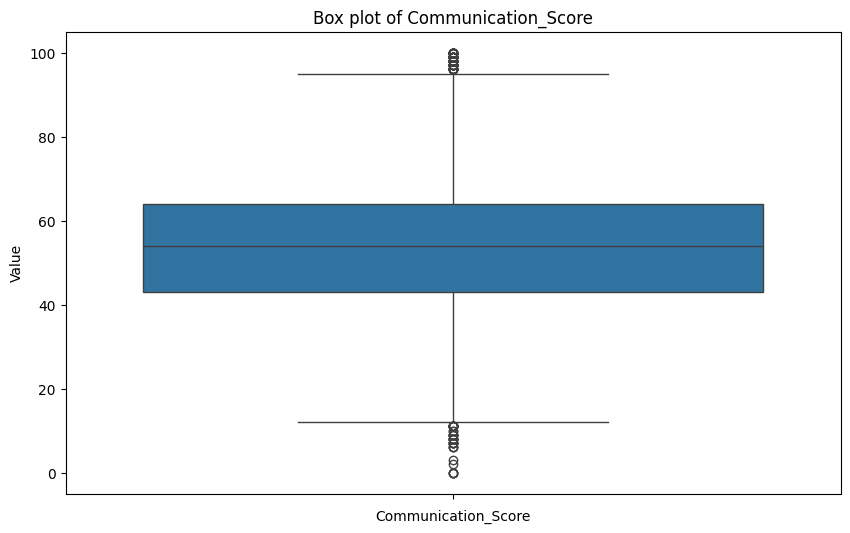

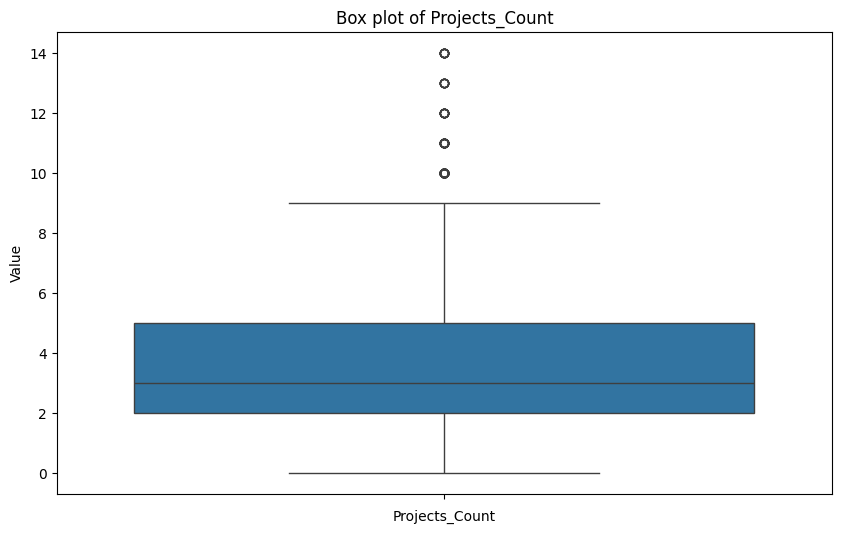

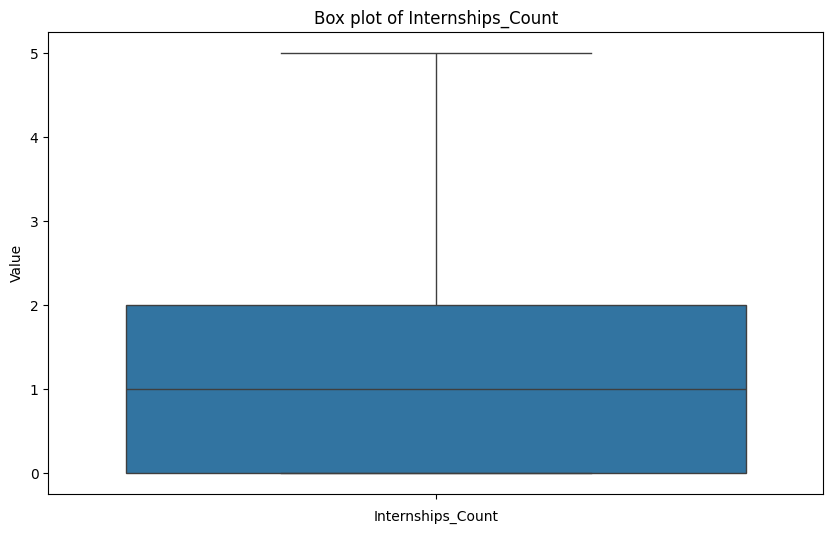

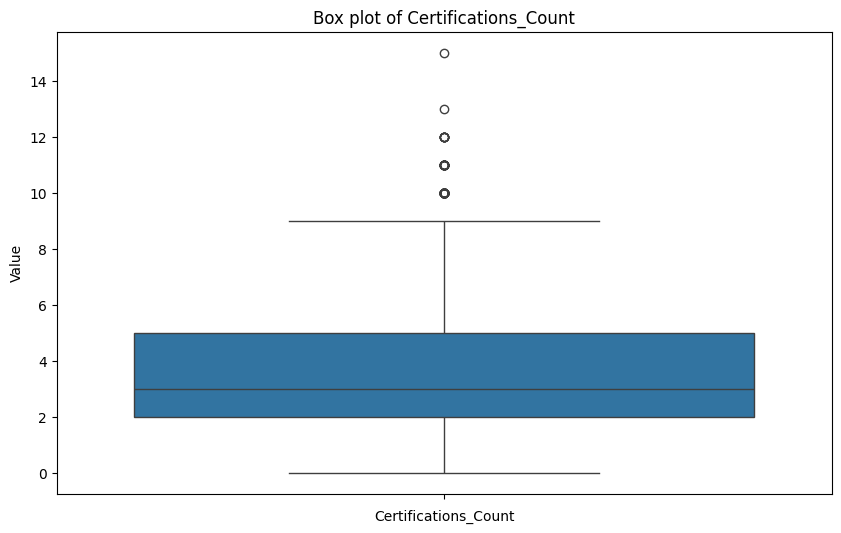

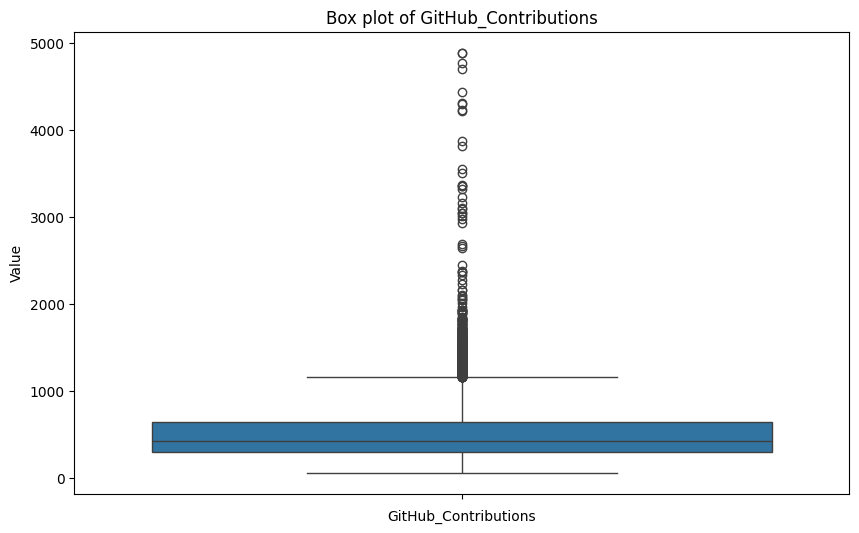

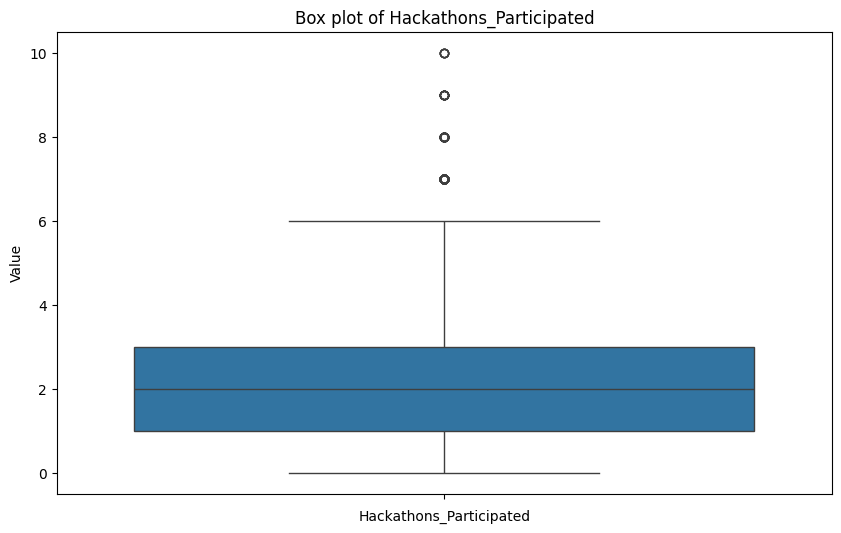

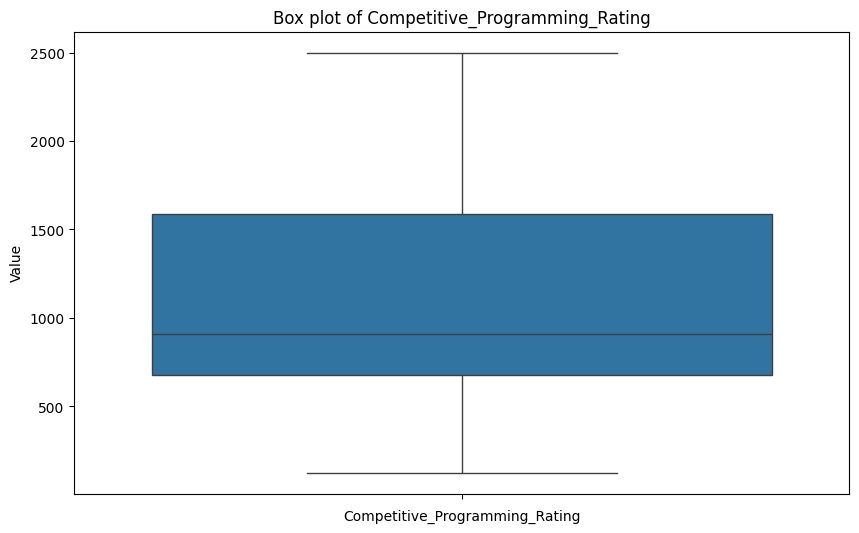

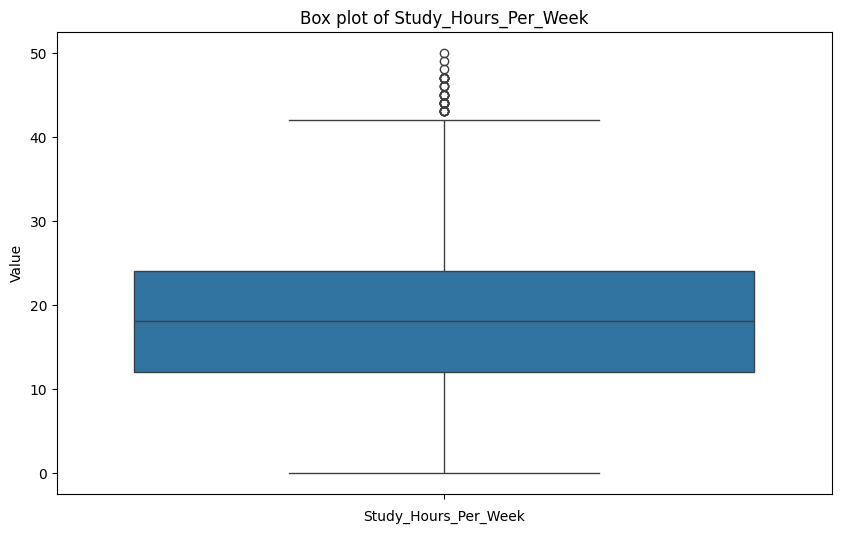

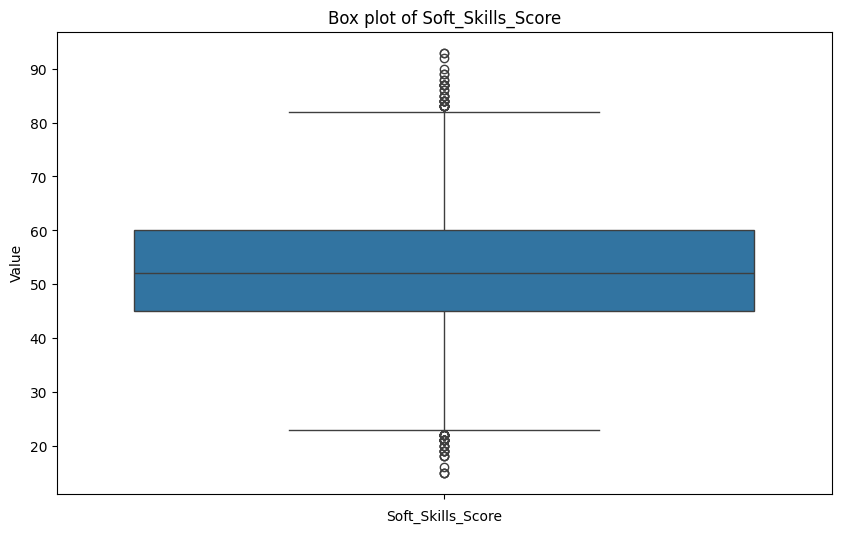

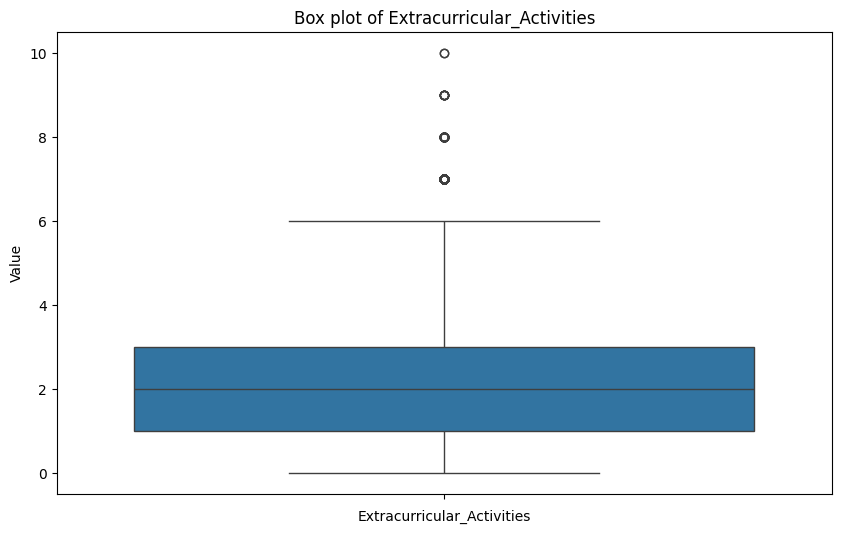

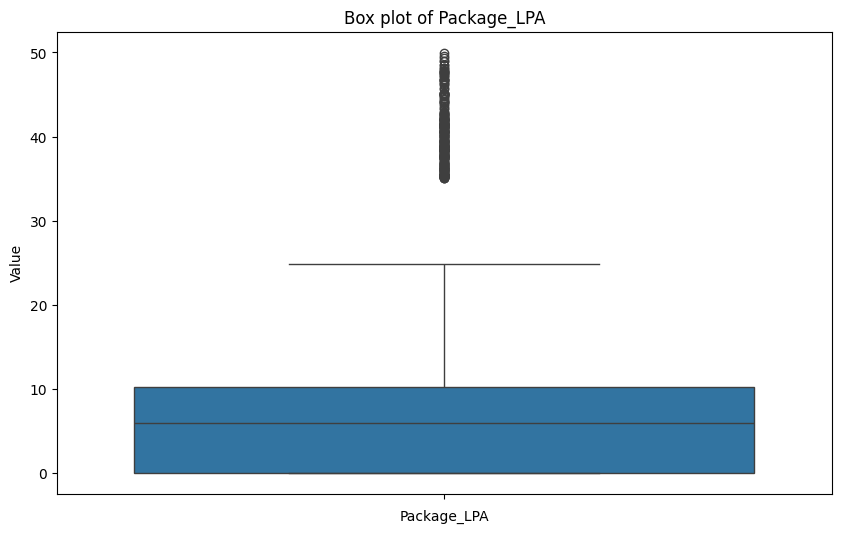

In [ ]:
# Here, col represents each numerical feature
for col in numerical_features:
  plt.figure(figsize = (10,6))
  sns.boxplot(df[col])
  plt.title(f"Box plot of {col}")
  plt.xlabel(col)
  plt.ylabel('Value')
  plt.show()

## Handling outliers

In [ ]:
q1 = df["Age"].quantile(0.25)
q3 = df["Age"].quantile(0.75)

iqr = q3 - q1
lower_bound = q1 - 1.5*iqr
upper_bound = q3 + 1.5*iqr

outlier = df[(df["Age"] < lower_bound) | (df['Age'] > upper_bound)]
print("outlier: \n", outlier)

df['Age'] = df['Age'].clip(lower= lower_bound, upper= upper_bound)

outlier: 
 Empty DataFrame
Columns: [Student_ID, Age, Gender, State, Branch, College_Tier, CGPA, Attendance_Percentage, DSA_Problems_Solved, Aptitude_Score, Communication_Score, Projects_Count, Internships_Count, Certifications_Count, Open_Source_Contributions, GitHub_Contributions, LinkedIn_Activity_Score, Hackathons_Participated, Competitive_Programming_Rating, Study_Hours_Per_Week, Soft_Skills_Score, Leadership_Experience, Extracurricular_Activities, Placement_Status, Package_LPA]
Index: []

[0 rows x 25 columns]


In [ ]:
X = df.drop(["State","Student_ID","Gender","Package_LPA"], axis=1)
y = df["Package_LPA"]
print(X)
# print("\nLabel: \n",y.min())

       Age      Branch College_Tier  CGPA  Attendance_Percentage  \
0       22  Mechanical       Tier-3  6.25                  67.07   
1       21  Mechanical       Tier-3  7.53                  87.69   
2       23          IT       Tier-3  7.90                  82.78   
3       22         CSE       Tier-3  7.00                  67.11   
4       19        AIML       Tier-2  6.23                  78.93   
...    ...         ...          ...   ...                    ...   
14995   23         CSE       Tier-1  7.35                  74.32   
14996   21        AIML       Tier-3  6.77                  61.31   
14997   19         CSE       Tier-2  8.09                  83.10   
14998   20          IT       Tier-2  6.75                  61.01   
14999   23         CSE       Tier-2  7.54                  79.07   

       DSA_Problems_Solved  Aptitude_Score  Communication_Score  \
0                       54              25                   76   
1                      115              49       

In [ ]:
df = df.drop(columns=["Gender", "State", "Student_ID", "Placement_Status"], axis = 1)

In [ ]:
# Shows relationship of original features with each other
corr = df.corr(numeric_only=True)

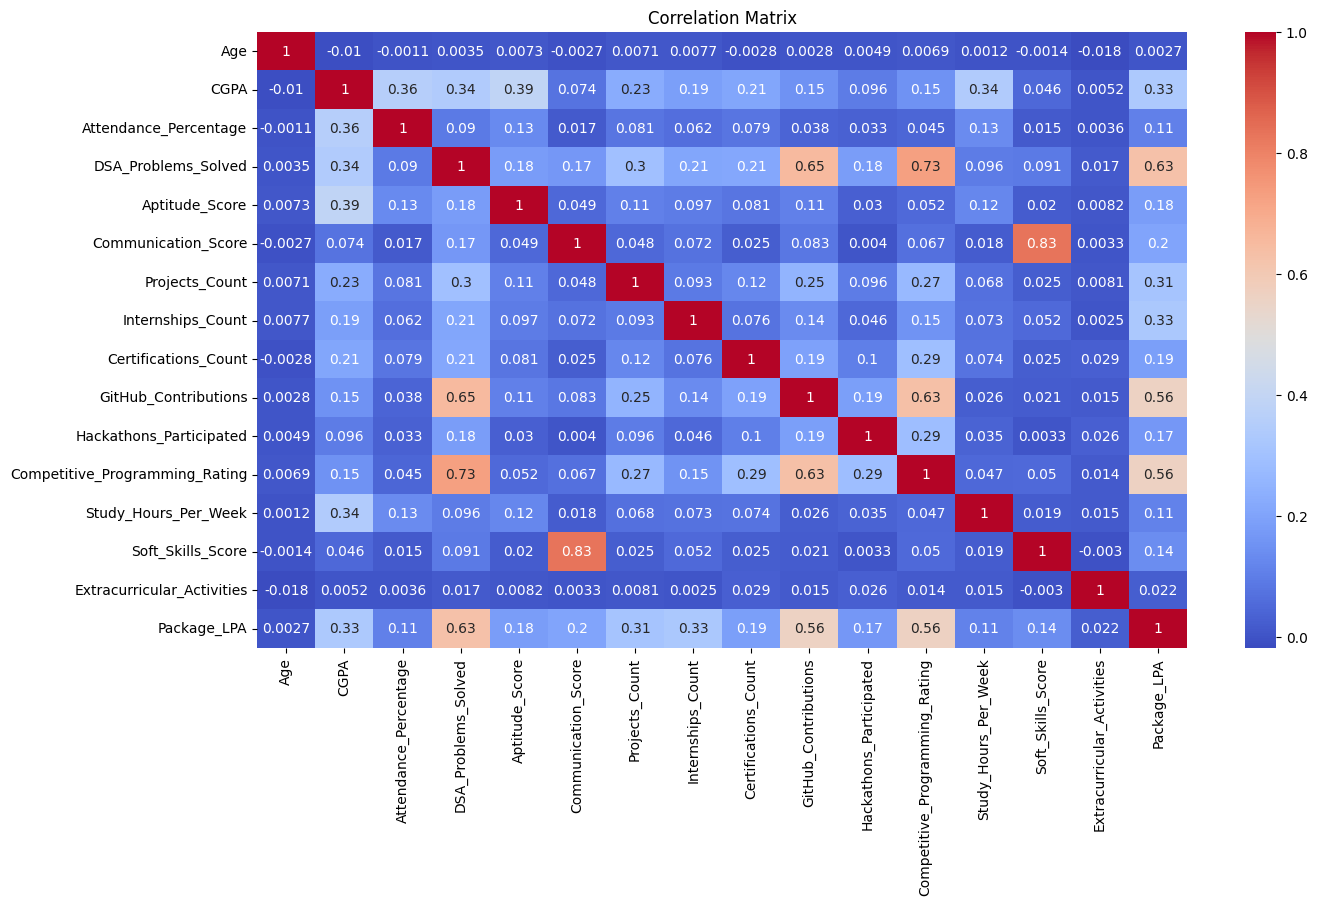

In [ ]:
fig = plt.figure(figsize=(15,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

#### By interpreting the above shown heatmap of correlation, three features are adding very less value to our target label i.e. Package_LPA

#### The three features are: Age, LinkedIn_Activity_Score and Extracurricular Activities. So we will drop them and then do the train & test split

### Extracting Important Features

In [ ]:
X = df.drop([
    "Age",
    "LinkedIn_Activity_Score",
    "Extracurricular_Activities",
    "Leadership_Experience",
    "Gender",
    "State",
    "Placement_Status",
    "Student_ID",
    "Package_LPA"
], axis=1)

y = df["Package_LPA"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### Scaling Numerical Features and encoding categorical features

In [ ]:
categorical_features = ["Branch", "College_Tier"]

numerical_features = [
    "CGPA",
    "Attendance_Percentage",
    "DSA_Problems_Solved",
    "Aptitude_Score",
    "Communication_Score",
    "Projects_Count",
    "Internships_Count",
    "Certifications_Count",
    "Open_Source_Contributions",
    "GitHub_Contributions",
    "Hackathons_Participated",
    "Competitive_Programming_Rating",
    "Study_Hours_Per_Week",
    "Soft_Skills_Score"
]
# Filling NaN values with median of the features
numerical_pipeline = [
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(numerical_pipeline), numerical_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features)
    ]
)

In [ ]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)


In [ ]:
print(y_train)

9839      8.84
9680      0.00
7093     40.54
11293     0.00
820       7.68
         ...  
5191      5.38
13418     6.85
5390     11.72
860       0.00
7270     38.25
Name: Package_LPA, Length: 12000, dtype: float64


### Baseline Model (Mean)

In [ ]:
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred_baseline)
mse = mean_squared_error(y_test, y_pred_baseline)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_baseline)

print("Baseline Model Performance")
print("--------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Baseline Model Performance
--------------------------
Mean Absolute Error: 5.30
Mean Squared Error: 53.14
Root Mean Squared Error: 7.29
R² Score: -0.0000


### MLR

In [ ]:
model = LinearRegression()
model.fit(X_train_preprocessed, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_preprocessed)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absoulute Error: {mae:,.2f}")
print(f"Mean Squared Error: {mse:,.2f}")
print(f"Root Mean Absoulute Error: {rmse:,.2f}")
print(f"R² Score: {r2:,.4f}")

Mean Absoulute Error: 3.25
Mean Squared Error: 20.71
Root Mean Absoulute Error: 4.55
R² Score: 0.6102


### Polynomial Regression

In [ ]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_preprocessed)
X_test_poly = poly.transform(X_test_preprocessed)

# Create and train model
poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

# Predictions
y_pred_poly = poly_model.predict(X_test_poly)

# Evaluation
mae = mean_absolute_error(y_test, y_pred_poly)
mse = mean_squared_error(y_test, y_pred_poly)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_poly)

print("Polynomial Regression Performance")
print("----------------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Polynomial Regression Performance
----------------------------------
Mean Absolute Error: 3.15
Mean Squared Error: 18.69
Root Mean Squared Error: 4.32
R² Score: 0.6484


### Ridge Regression

In [ ]:
ridge_model = Ridge(alpha=5)
ridge_model.fit(X_train_preprocessed, y_train)
y_pred_ridge = ridge_model.predict(X_test_preprocessed)

In [ ]:
mae = mean_absolute_error(y_test, y_pred_ridge)
mse = mean_squared_error(y_test, y_pred_ridge)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Performance")
print("----------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Ridge Regression Performance
----------------------------
Mean Absolute Error: 3.25
Mean Squared Error: 20.71
Root Mean Squared Error: 4.55
R² Score: 0.6102


### Lasso Regression

In [ ]:
lasso_model = Lasso(alpha=1.0)

lasso_model.fit(X_train_preprocessed, y_train)

y_pred_lasso = lasso_model.predict(X_test_preprocessed)

mae = mean_absolute_error(y_test, y_pred_lasso)
mse = mean_squared_error(y_test, y_pred_lasso)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Performance")
print("----------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Lasso Regression Performance
----------------------------
Mean Absolute Error: 3.76
Mean Squared Error: 28.36
Root Mean Squared Error: 5.33
R² Score: 0.4662


### Decison Tree

In [ ]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train_preprocessed, y_train)

y_pred_dt = dt_model.predict(X_test_preprocessed)

mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression Performance")
print("------------------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Decision Tree Regression Performance
------------------------------------
Mean Absolute Error: 4.19
Mean Squared Error: 38.47
Root Mean Squared Error: 6.20
R² Score: 0.2760


### Random Forest

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_preprocessed, y_train)

y_pred_rf = rf_model.predict(X_test_preprocessed)

mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Performance")
print("------------------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Random Forest Regression Performance
------------------------------------
Mean Absolute Error: 3.21
Mean Squared Error: 19.17
Root Mean Squared Error: 4.38
R² Score: 0.6392


### XGBoost

In [ ]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train_preprocessed, y_train)

y_pred_gb = gb_model.predict(X_test_preprocessed)

mae = mean_absolute_error(y_test, y_pred_gb)
mse = mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Regression Performance")
print("----------------------------------------")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Gradient Boosting Regression Performance
----------------------------------------
Mean Absolute Error: 3.14
Mean Squared Error: 18.35
Root Mean Squared Error: 4.28
R² Score: 0.6547


### Comparison of all models

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear": y_pred,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "Polynomial": y_pred_poly,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

mae_scores = {}
rmse_scores = {}
r2_scores = {}

for name, pred in models.items():
    mae_scores[name] = mean_absolute_error(y_test, pred)
    rmse_scores[name] = np.sqrt(mean_squared_error(y_test, pred))
    r2_scores[name] = r2_score(y_test, pred)

# Define colors for the bars, highlighting the best model
model_names = list(mae_scores.keys())
colors = ['skyblue' if name != best_model_name else 'red' for name in model_names]

# Plot MAE
plt.figure(figsize=(10, 5))
plt.bar(model_names, mae_scores.values(), color=colors)
plt.title("Model Comparison - MAE")
plt.ylabel("MAE")
plt.xticks(rotation=30)
plt.show()

# Plot RMSE
plt.figure(figsize=(10, 5))
plt.bar(model_names, rmse_scores.values(), color=colors)
plt.title("Model Comparison - RMSE")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.show()

# Plot R²
plt.figure(figsize=(10, 5))
plt.bar(model_names, r2_scores.values(), color=colors)
plt.title("Model Comparison - R² Score")
plt.ylabel("R²")
plt.xticks(rotation=30)
plt.show()

NameError: name 'y_pred' is not defined

In [ ]:
# --------------------------------------------------
# 1. Store predictions from all models
# --------------------------------------------------

models = {
    "Linear Regression": y_pred,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "Polynomial Regression": y_pred_poly,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

# --------------------------------------------------
# 2. Calculate performance metrics
# --------------------------------------------------

results = []

for name, pred in models.items():

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print("=" * 80)
print(results_df.round(4).to_string(index=False))


# --------------------------------------------------
# 3. Identify best model based on R²
# --------------------------------------------------

best_model_name = results_df.loc[
    results_df["R²"].idxmax(), "Model"
]

best_prediction = models[best_model_name]

print("\nBEST MODEL")
print("=" * 80)
print(best_model_name)


# --------------------------------------------------
# 4. MAE Comparison
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("Model Comparison - MAE")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 5. RMSE Comparison
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.title("Model Comparison - RMSE")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. R² Comparison
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["R²"])

plt.title("Model Comparison - R² Score")
plt.ylabel("R² Score (Higher is Better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Actual vs Predicted for Best Model
# --------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(y_test, best_prediction)

# Perfect prediction line
minimum = min(y_test.min(), best_prediction.min())
maximum = max(y_test.max(), best_prediction.max())

plt.plot([minimum, maximum], [minimum, maximum])

plt.xlabel("Actual Package (LPA)")
plt.ylabel("Predicted Package (LPA)")
plt.title(f"Actual vs Predicted - {best_model_name}")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 8. Residual Analysis
# --------------------------------------------------

residuals = y_test - best_prediction

plt.figure(figsize=(8, 5))

plt.scatter(best_prediction, residuals)

plt.axhline(y=0)

plt.xlabel("Predicted Package (LPA)")
plt.ylabel("Residual")
plt.title(f"Residual Plot - {best_model_name}")

plt.tight_layout()
plt.show()

NameError: name 'y_pred' is not defined